# PA43 — Weather stream exploration
Faro and Angra do Heroísmo · 2021–2025 · T1: precipitation ≥ 0.1 mm.

Run all cells in order from the repository root or the notebooks folder.
Figures and complete tables are exported to `results/eda/`; raw data remain unchanged.

## 0. Setup and data loading

In [1]:
# Import libraries and configure paths, units and city colours.
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/features.py").exists() and (p / "data/raw").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or notebooks folder.")
sys.path.insert(0, str(ROOT / "src"))
from features import add_target

OUT = ROOT / "results/eda"
(OUT / "figures").mkdir(parents=True, exist_ok=True)
(OUT / "tables").mkdir(parents=True, exist_ok=True)
WEATHER = ["temperature_2m", "relative_humidity_2m", "precipitation", "wind_speed_10m"]
UNITS = {"temperature_2m": "Temperature (°C)", "relative_humidity_2m": "Humidity (%)",
         "precipitation": "Precipitation (mm)", "wind_speed_10m": "Wind speed (km/h)"}
COLORS = {"Faro": "#D97928", "Angra": "#267A9E"}
ZONES = {"Faro": "Europe/Lisbon", "Angra": "Atlantic/Azores"}
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.2})

In [2]:
# Export complete tables and figures; preview long tables only.
def save_table(table, name, preview_rows=10):
    table.to_csv(OUT / "tables" / f"{name}.csv")
    display(table if len(table) <= preview_rows else table.head(preview_rows))
    if len(table) > preview_rows:
        print(f"Showing {preview_rows} of {len(table)} rows; the complete table was exported.")

def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / "figures" / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [3]:
# Load both raw datasets and interpret GMT timestamps as UTC.
raw = {
    city: pd.read_csv(ROOT / "data/raw" / f"{city.lower()}_2021_2025.csv")
    for city in COLORS
}
for df in raw.values():
    df["time"] = pd.to_datetime(df["time"], utc=True, errors="coerce")
for city, df in raw.items():
    print(city, df.shape)
    display(df.head(3))

Faro (43824, 5)


,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
0,2021-01-01 00:00:00+00:00,12.1,84,0.0,16.0
1,2021-01-01 01:00:00+00:00,11.6,83,0.0,13.7
2,2021-01-01 02:00:00+00:00,11.0,79,0.0,16.6


Angra (43824, 5)


,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
0,2021-01-01 00:00:00+00:00,13.7,82,0.0,12.6
1,2021-01-01 01:00:00+00:00,13.7,83,0.0,13.4
2,2021-01-01 02:00:00+00:00,13.6,84,0.0,12.6


## 1. Data quality and chronology
Check values and hourly coverage before creating temporal indicators.
Investigate failed checks rather than silently deleting or replacing observations.

### 1.1. Value quality

In [4]:
# Check missing values, repeated rows and basic physical bounds.
value_rows = []
for city, df in raw.items():
    value_rows.append({
        "city": city, "rows": len(df),
        "missing_weather_values": int(df[WEATHER].isna().sum().sum()),
        "nonfinite_weather_values": int((~np.isfinite(df[WEATHER])).sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "invalid_humidity": int((~df["relative_humidity_2m"].between(0, 100)).sum()),
        "negative_precipitation": int(df["precipitation"].lt(0).sum()),
        "negative_wind": int(df["wind_speed_10m"].lt(0).sum()),
    })
value_quality = pd.DataFrame(value_rows).set_index("city")
display(value_quality.T)

city,Faro,Angra
rows,43824,43824
missing_weather_values,0,0
nonfinite_weather_values,0,0
duplicate_rows,0,0
invalid_humidity,0,0
negative_precipitation,0,0
negative_wind,0,0


### 1.2. Hourly coverage

In [5]:
# Check the expected period, timestamp uniqueness and hourly order.
expected = pd.date_range("2021-01-01", "2025-12-31 23:00", freq="h", tz="UTC")
time_rows = []
for city, df in raw.items():
    times = pd.DatetimeIndex(df["time"].dropna())
    time_rows.append({
        "city": city, "invalid_timestamps": int(df["time"].isna().sum()),
        "duplicate_timestamps": int(df["time"].duplicated().sum()),
        "missing_hours": len(expected.difference(times)),
        "unexpected_timestamps": len(times.difference(expected)),
        "chronological": df["time"].is_monotonic_increasing,
        "non_hourly_steps": int(df["time"].diff().dropna().ne(pd.Timedelta(hours=1)).sum()),
    })
time_quality = pd.DataFrame(time_rows).set_index("city")
display(time_quality.T)
quality = value_quality.join(time_quality)
quality.to_csv(OUT / "tables/quality_checks.csv")

city,Faro,Angra
invalid_timestamps,0,0
duplicate_timestamps,0,0
missing_hours,0,0
unexpected_timestamps,0,0
chronological,True,True
non_hourly_steps,0,0


In [6]:
# Stop if the data cannot support complete hourly windows.
count_checks = quality.drop(columns=["rows", "chronological"])
assert count_checks.eq(0).all().all(), "Investigate the quality tables before continuing."
assert quality["chronological"].all(), "Check timestamp ordering before continuing."
print("Data quality and chronology checks passed.")

Data quality and chronology checks passed.


### 1.3. Target and time columns

In [7]:
# Apply the shared T1 definition and create UTC calendar and local-hour columns.
streams = {city: add_target(df.copy()) for city, df in raw.items()}
for city, df in streams.items():
    df["local_time"] = df["time"].dt.tz_convert(ZONES[city])
    df["year"] = df["time"].dt.year
    df["month"] = df["time"].dt.month
    df["local_hour"] = df["local_time"].dt.hour

## 2. Weather statistics and distributions
Review the minimum, maximum and quartiles for plausible extremes; do not automatically remove them.
Histograms use all hours, common bins and linear counts. Precipitation near zero may dominate its histogram.

In [8]:
# Compare descriptive statistics for the four weather variables.
descriptive = pd.concat({city: df[WEATHER].describe().T for city, df in streams.items()},
                        names=["city", "variable"])
save_table(descriptive.round(3), "weather_statistics")

count    mean     std   min   25%   50%   75%  \
city  variable                                                                
Faro  temperature_2m        43824.0  18.807   5.515   2.5  14.8  18.4  22.6   
      relative_humidity_2m  43824.0  69.342  17.638   8.0  57.0  71.0  84.0   
      precipitation         43824.0   0.060   0.408   0.0   0.0   0.0   0.0   
      wind_speed_10m        43824.0  12.855   6.909   0.0   7.6  11.9  17.1   
Angra temperature_2m        43824.0  17.626   3.547   6.3  15.0  17.2  20.2   
      relative_humidity_2m  43824.0  85.293  10.935  46.0  77.0  87.0  95.0   
      precipitation         43824.0   0.212   0.689   0.0   0.0   0.0   0.1   
      wind_speed_10m        43824.0  13.876   8.413   0.0   7.1  12.6  19.2   

                              max  
city  variable                     
Faro  temperature_2m         39.5  
      relative_humidity_2m  100.0  
      precipitation          22.8  
      wind_speed_10m         56.6  
Angra temperature_2m         29.4  
      relative_humidity_2m  100.0  
      precipitation          19.7  
      wind_speed_10m         58.4

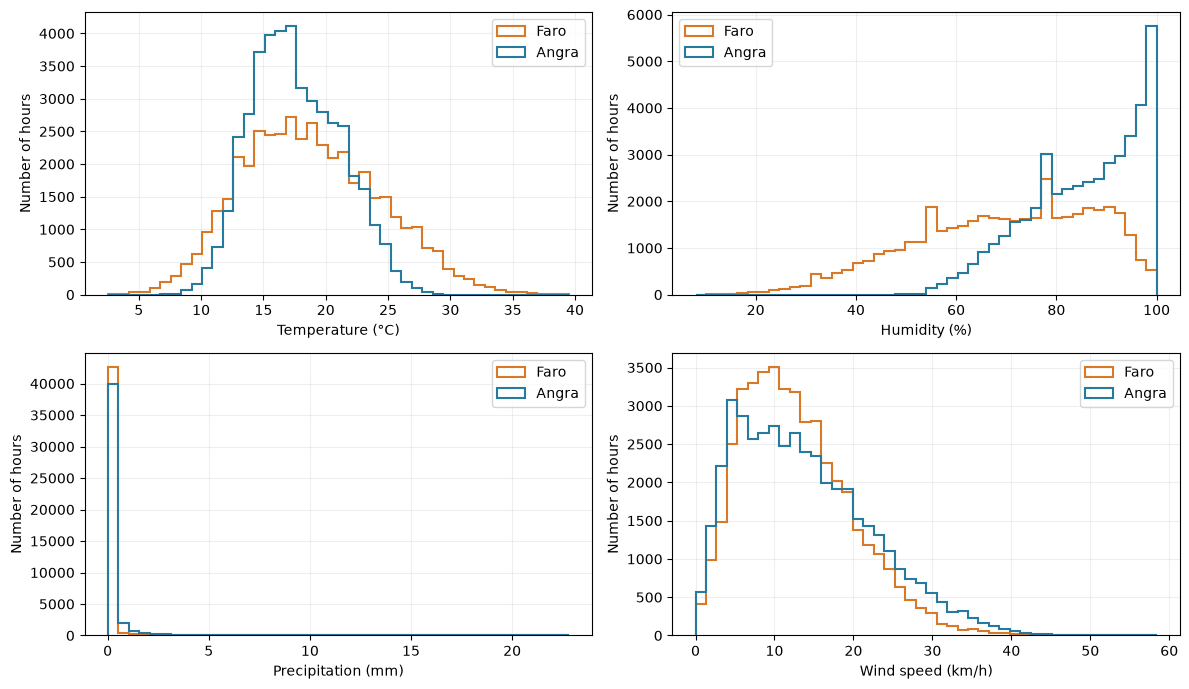

In [9]:
# Compare full distributions using shared bins and hourly counts.
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for variable, ax in zip(WEATHER, axes.flat):
    values = pd.concat([df[variable] for df in streams.values()])
    bins = np.linspace(values.min(), values.max(), 45)
    for city, df in streams.items():
        ax.hist(df[variable], bins=bins, histtype="step", density=False,
                color=COLORS[city], label=city, linewidth=1.5)
    ax.set(xlabel=UNITS[variable], ylabel="Number of hours")
    ax.legend()
save_plot(fig, "weather_distributions")

## 3. Rain events and temporal patterns

### 3.1. Target distribution

In [10]:
# Summarise rainy and dry hours using the same target in both cities.
target_summary = pd.DataFrame({city: {"hours": len(df), "rain_hours": int(df["rain_event"].sum()),
    "dry_hours": int(df["rain_event"].eq(0).sum()), "rain_rate_pct": 100 * df["rain_event"].mean()}
    for city, df in streams.items()}).T
save_table(target_summary.round(3), "target_summary")

,hours,rain_hours,dry_hours,rain_rate_pct
Faro,43824.0,3879.0,39945.0,8.851
Angra,43824.0,17034.0,26790.0,38.869


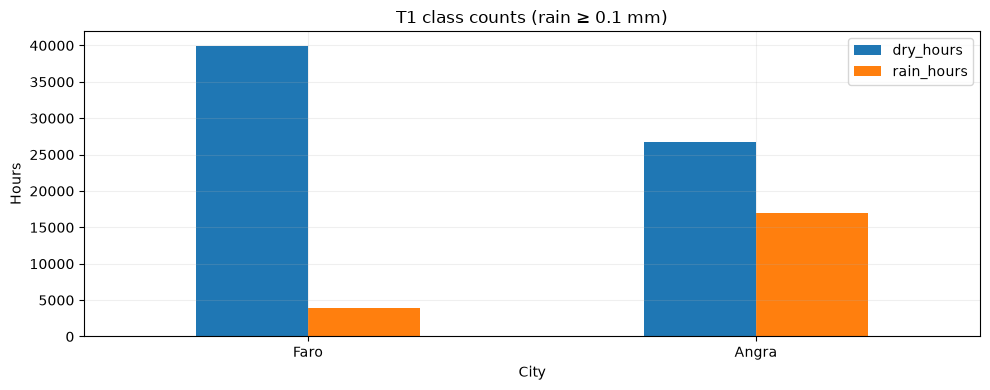

In [11]:
# Compare the number of hours in each target class.
fig, ax = plt.subplots()
target_summary[["dry_hours", "rain_hours"]].plot.bar(ax=ax, rot=0)
ax.set(xlabel="City", ylabel="Hours", title="T1 class counts (rain ≥ 0.1 mm)")
save_plot(fig, "target_distribution")

### 3.2. Annual rain frequency

In [12]:
# Calculate the percentage of rainy hours in each UTC year.
annual = pd.DataFrame({city: df.groupby("year")["rain_event"].mean() * 100
                       for city, df in streams.items()})
save_table(annual.round(3), "annual_rain_rate")

,Faro,Angra
year,,
2021,8.516,39.463
2022,9.041,37.066
2023,6.575,40.091
2024,8.925,39.162
2025,11.199,38.562


### 3.3. Monthly seasonality

In [13]:
# Pool the same calendar month across all five years.
seasonal = pd.DataFrame({city: df.groupby("month")["rain_event"].mean() * 100
                         for city, df in streams.items()})
save_table(seasonal.round(3), "seasonal_rain_rate", preview_rows=12)

,Faro,Angra
month,,
1,10.296,46.048
2,13.682,42.287
3,18.468,38.468
4,12.556,48.389
5,4.274,42.392
6,4.722,33.917
7,0.108,31.048
8,0.323,32.581
9,6.028,31.778


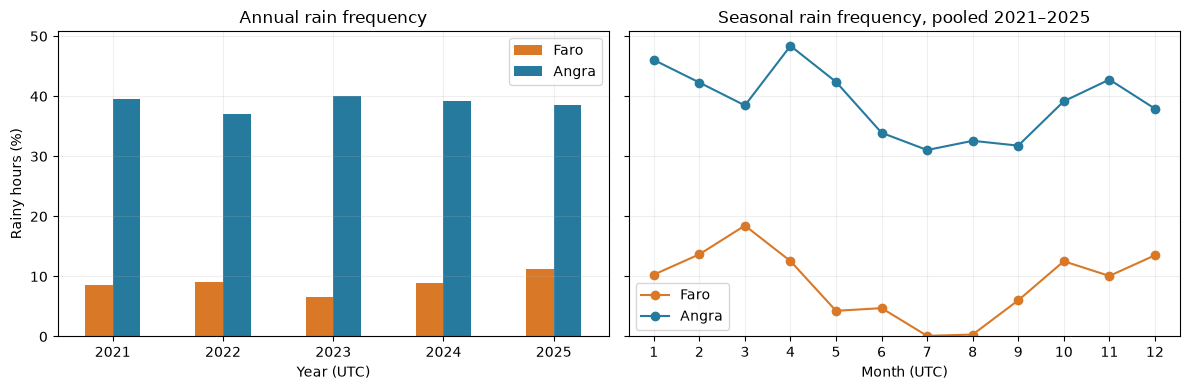

In [14]:
# Plot annual frequency and monthly seasonality on a shared scale.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
annual.plot.bar(ax=axes[0], color=list(COLORS.values()), rot=0)
seasonal.plot(ax=axes[1], color=list(COLORS.values()), marker="o")
axes[0].set(title="Annual rain frequency", xlabel="Year (UTC)", ylabel="Rainy hours (%)")
axes[1].set(title="Seasonal rain frequency, pooled 2021–2025", xlabel="Month (UTC)", xticks=range(1, 13))
save_plot(fig, "annual_and_seasonal_rain")

### 3.4. Monthly weather and rain evolution

In [15]:
# Calculate monthly means and export the full chronological table.
monthly = {city: df.set_index("time")[WEATHER + ["rain_event"]].resample("MS").mean()
           for city, df in streams.items()}
save_table(pd.concat(monthly, names=["city", "month_utc"]).round(4), "monthly_means")

temperature_2m  relative_humidity_2m  \
city month_utc                                                         
Faro 2021-01-01 00:00:00+00:00         11.1675               80.1546   
     2021-02-01 00:00:00+00:00         13.9711               83.4777   
     2021-03-01 00:00:00+00:00         14.9460               67.9933   
     2021-04-01 00:00:00+00:00         16.8615               78.8292   
     2021-05-01 00:00:00+00:00         19.6050               61.6868   
     2021-06-01 00:00:00+00:00         21.3019               64.1083   
     2021-07-01 00:00:00+00:00         24.5353               55.7366   
     2021-08-01 00:00:00+00:00         24.7191               59.2675   
     2021-09-01 00:00:00+00:00         22.3362               71.9167   
     2021-10-01 00:00:00+00:00         20.8145               68.2984   

                                precipitation  wind_speed_10m  rain_event  
city month_utc                                                             
Faro 2021-01-01 00:00:00+00:00         0.0556         13.4417      0.1035  
     2021-02-01 00:00:00+00:00         0.1637         14.3141      0.2634  
     2021-03-01 00:00:00+00:00         0.0145         13.5474      0.0430  
     2021-04-01 00:00:00+00:00         0.0726         12.6012      0.2278  
     2021-05-01 00:00:00+00:00         0.0073         12.8413      0.0134  
     2021-06-01 00:00:00+00:00         0.0121         12.5136      0.0542  
     2021-07-01 00:00:00+00:00         0.0000         13.3110      0.0000  
     2021-08-01 00:00:00+00:00         0.0004         11.9031      0.0040  
     2021-09-01 00:00:00+00:00         0.0578         10.8776      0.0597  
     2021-10-01 00:00:00+00:00         0.0284         12.1735      0.0793

Showing 10 of 120 rows; the complete table was exported.


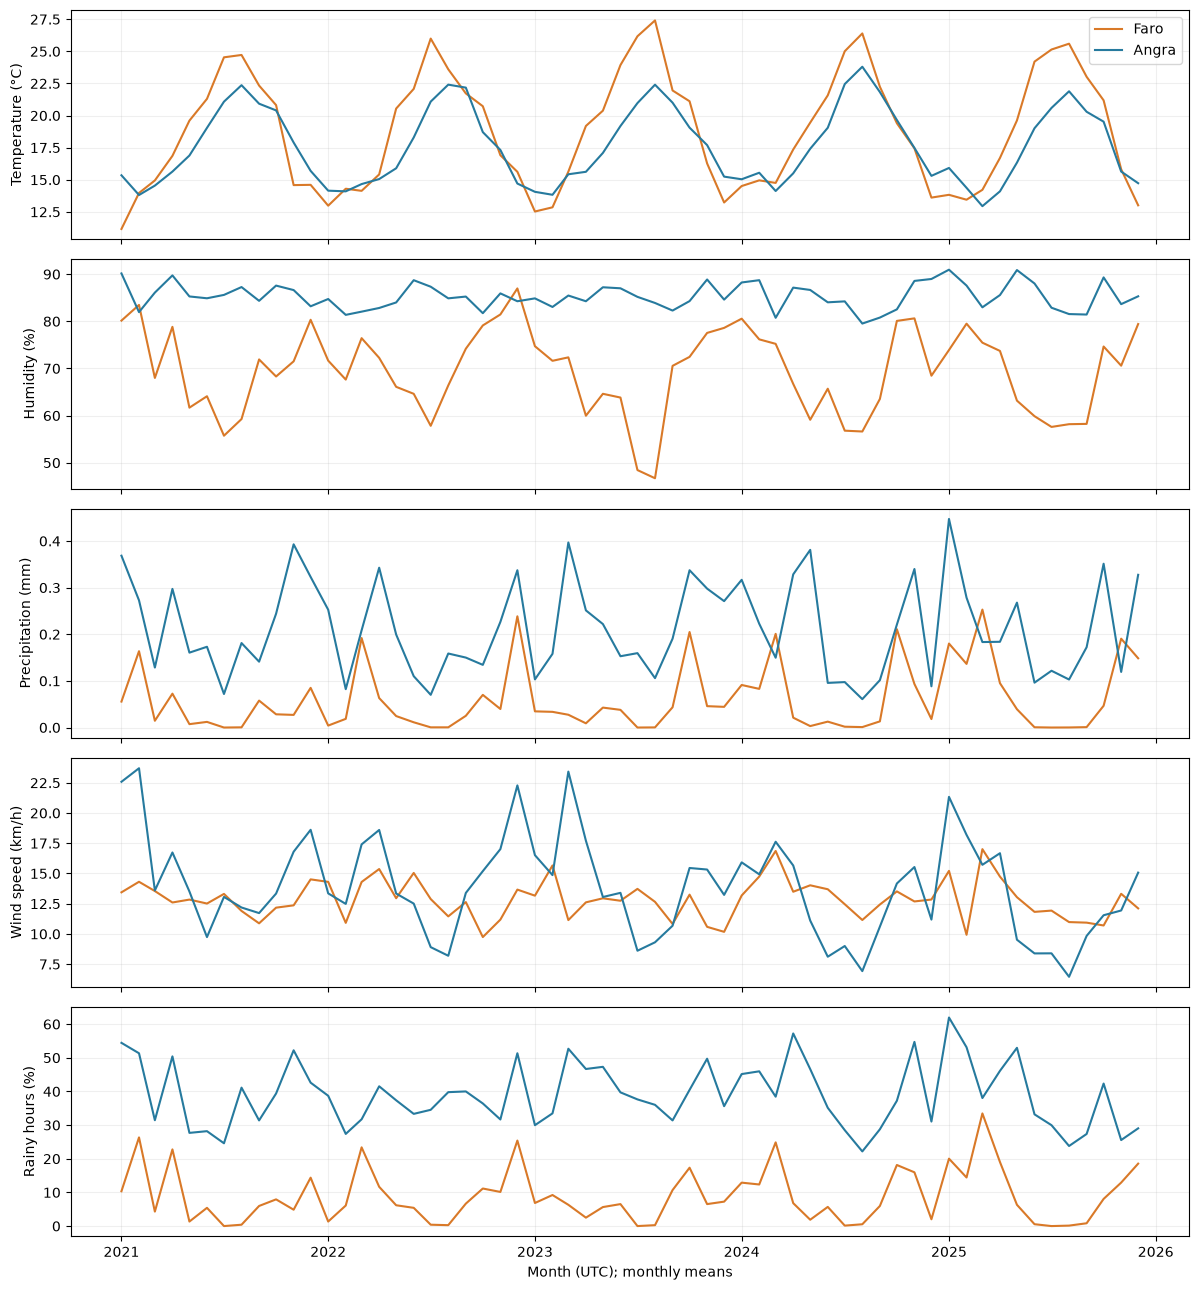

In [16]:
# Compare monthly weather means and rain frequency over time.
fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True)
for variable, ax in zip(WEATHER + ["rain_event"], axes):
    for city, df in monthly.items():
        values = df[variable] * (100 if variable == "rain_event" else 1)
        ax.plot(df.index, values, label=city, color=COLORS[city])
    ax.set_ylabel("Rainy hours (%)" if variable == "rain_event" else UNITS[variable])
axes[0].legend()
axes[-1].set_xlabel("Month (UTC); monthly means")
save_plot(fig, "monthly_weather_and_target")

### 3.5. Previous 24-hour rain rate

In [17]:
# Measure rain frequency in the 24 hours strictly before each observation.
for df in streams.values():
    df["rain_previous_24h_pct"] = df["rain_event"].shift(1).rolling(24, min_periods=24).mean() * 100
rolling_summary = pd.DataFrame({city: df["rain_previous_24h_pct"].describe() for city, df in streams.items()})
save_table(rolling_summary.round(3), "rolling_rain_summary")

,Faro,Angra
count,43800.000,43800.000
mean,8.851,38.882
std,18.803,28.219
min,0.000,0.000
25%,0.000,16.667
50%,0.000,33.333
75%,8.333,58.333
max,100.000,100.000


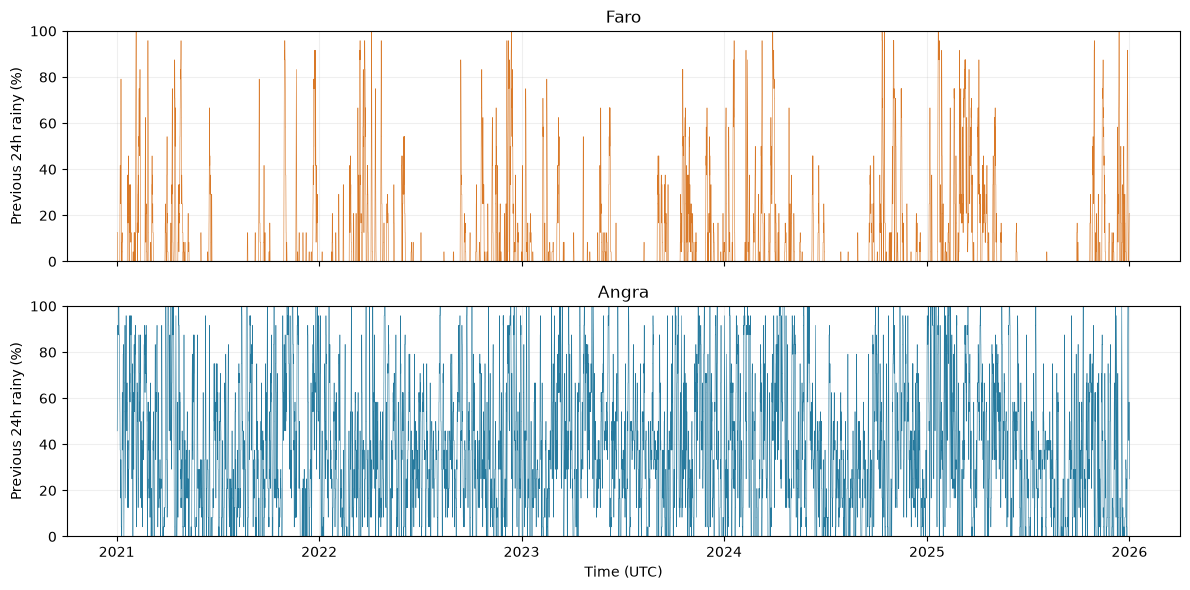

In [18]:
# Use the same time and percentage scales for both cities.
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for (city, df), ax in zip(streams.items(), axes):
    ax.plot(df["time"], df["rain_previous_24h_pct"], color=COLORS[city], linewidth=0.4)
    ax.set(title=city, ylabel="Previous 24h rainy (%)", ylim=(0, 100))
axes[-1].set_xlabel("Time (UTC)")
save_plot(fig, "rolling_rain_24h")

### 3.6. Rain frequency by local hour

In [19]:
# Group rain frequency by local hour, accounting for daylight saving time.
local_hour_profile = pd.DataFrame({city: df.groupby("local_hour")["rain_event"].mean() * 100
                                   for city, df in streams.items()})
save_table(local_hour_profile.round(3), "local_hour_rain_rate")

,Faro,Angra
local_hour,,
0,7.503,27.327
1,7.229,27.656
2,7.777,29.244
3,7.886,28.368
4,7.831,28.861
5,8.215,27.711
6,8.708,28.478
7,8.269,28.423
8,8.872,30.504


Showing 10 of 24 rows; the complete table was exported.


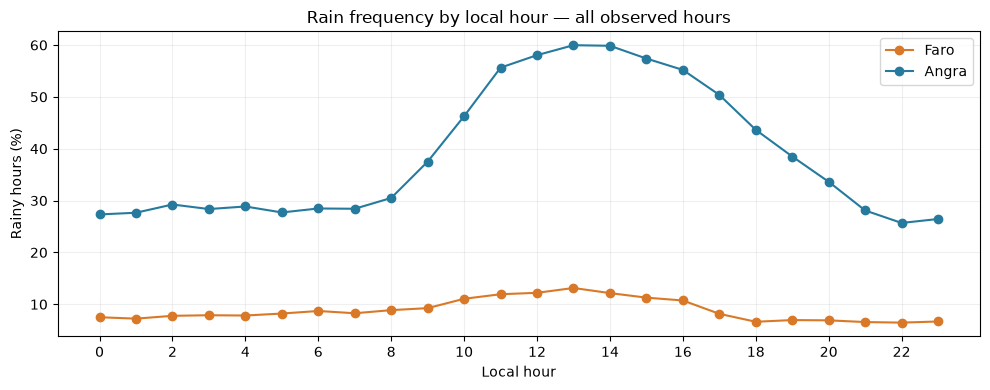

In [20]:
# Compare rain frequency across local hours of the day.
fig, ax = plt.subplots()
local_hour_profile.plot(ax=ax, color=list(COLORS.values()), marker="o")
ax.set(xlabel="Local hour", ylabel="Rainy hours (%)", xticks=range(0, 24, 2),
       title="Rain frequency by local hour — all observed hours")
save_plot(fig, "local_hour_rain")

## 4. Rain-free excursion windows
A 3- or 6-hour window is rain-free when every hour, including its start, has no T1 event.
Consider all possible start hours and exclude incomplete windows at the end of the dataset.
These overlapping windows describe past conditions; they are not independent excursions or prediction inputs.

In [21]:
# Align each complete rolling window with its start hour.
EXCURSION_HOURS = (3, 6)

def dry_window_success(events, duration):
    rain_count = events.rolling(duration, min_periods=duration).sum().shift(-(duration - 1))
    return rain_count.eq(0).astype(float).where(rain_count.notna())

for df in streams.values():
    for duration in EXCURSION_HOURS:
        df[f"dry_window_{duration}h"] = dry_window_success(df["rain_event"], duration)

In [22]:
# Summarise eligible starts and rain-free percentages overall and by UTC month.
window_rows = []
monthly_window_rows = []
for city, df in streams.items():
    for duration in EXCURSION_HOURS:
        indicator = df[f"dry_window_{duration}h"]
        window_rows.append({"city": city, "duration_h": duration,
            "eligible_starts": int(indicator.count()), "excluded_incomplete": int(indicator.isna().sum()),
            "dry_starts": int(indicator.sum()), "dry_start_pct": indicator.mean() * 100})
        for month, values in indicator.groupby(df["month"]):
            monthly_window_rows.append({"city": city, "duration_h": duration, "month_utc": month,
                "eligible_starts": int(values.count()), "dry_start_pct": values.mean() * 100})
window_summary = pd.DataFrame(window_rows).set_index(["city", "duration_h"])
window_monthly = pd.DataFrame(monthly_window_rows)
save_table(window_summary.round(3), "excursion_window_summary")
window_monthly.to_csv(OUT / "tables/excursion_windows_by_month.csv", index=False)

eligible_starts  excluded_incomplete  dry_starts  \
city  duration_h                                                     
Faro  3                     43822                    2       38122   
      6                     43819                    5       36364   
Angra 3                     43822                    2       21736   
      6                     43819                    5       16954   

                  dry_start_pct  
city  duration_h                 
Faro  3                  86.993  
      6                  82.987  
Angra 3                  49.601  
      6                  38.691

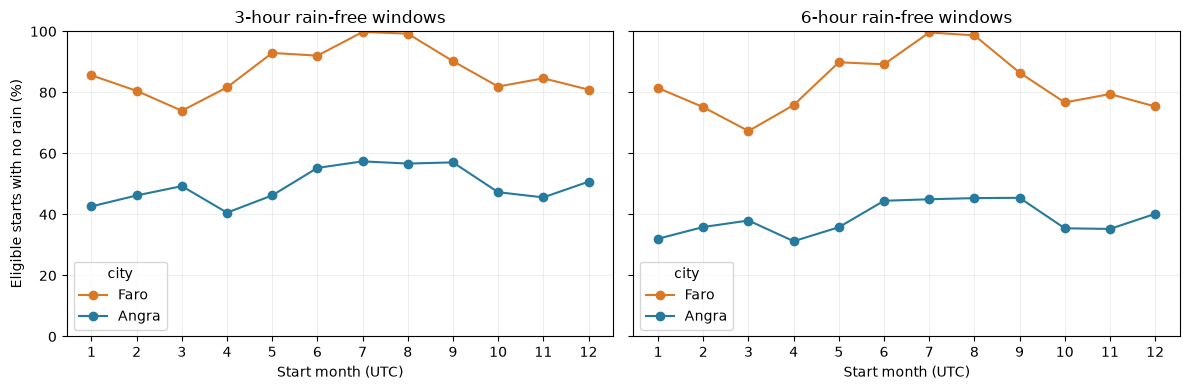

In [23]:
# Compare 3-hour and 6-hour rain-free windows by start month.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for duration, ax in zip(EXCURSION_HOURS, axes):
    table = window_monthly.loc[window_monthly["duration_h"].eq(duration)].pivot(
        index="month_utc", columns="city", values="dry_start_pct").reindex(columns=list(streams))
    table.plot(ax=ax, color=list(COLORS.values()), marker="o")
    ax.set(title=f"{duration}-hour rain-free windows", xlabel="Start month (UTC)",
           ylabel="Eligible starts with no rain (%)", ylim=(0, 100), xticks=range(1, 13))
save_plot(fig, "excursion_windows_by_month")

## 5. Final checks and exports
Check the target and window alignment. Complete tables and figures are saved in `results/eda/`.

In [24]:
# Verify the target, past-only rolling rate and incomplete excursion windows.
example = pd.Series([0, 0, 0, 1, 0, 0, 0])
np.testing.assert_allclose(dry_window_success(example, 3), [1, 0, 0, 0, 1, np.nan, np.nan], equal_nan=True)
for city, df in streams.items():
    assert df["rain_event"].equals(df["precipitation"].ge(0.1).astype(int))
    assert df["rain_previous_24h_pct"].iloc[:24].isna().all()
    assert df["rain_previous_24h_pct"].iloc[24] == df["rain_event"].iloc[:24].mean() * 100
    for duration in EXCURSION_HOURS:
        indicator = df[f"dry_window_{duration}h"]
        assert indicator.count() == len(df) - duration + 1
        assert indicator.iloc[-(duration - 1):].isna().all()
print("Checks passed. Exports:", OUT)

Checks passed. Exports: C:\Users\Pinho\Desktop\IMS\1st Year Masters\Data Stream Mining\Pratical Assignment 1\PA43-Data_Stream_Mining\results\eda
